# 15 — Body progress & change analysis

**Research question:** Có thể khôi phục xu hướng định trước, giữ nguồn riêng và ngừng tính trend khi thiếu dữ liệu/quality chưa đủ không?

Dataset synthetic v1, seed 42 (generator xác định). Baseline: daily median → calendar/rolling-week medians → Theil-Sen slope theo ngày thực tế, chỉ trên reviewed observations.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Module_01_User_and_Body_Profile.md").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display, Markdown
config = json.loads((ROOT / "configs/progress_phase4.json").read_text(encoding="utf-8"))
progress = json.loads((ROOT / "experiments/body_progress_phase4/progress.json").read_text(encoding="utf-8"))


In [2]:
metrics = json.loads((ROOT / "experiments/body_progress_phase4/metrics.json").read_text())
print("Expected slope (fixture only):", metrics["expected_primary_slope_kg_per_week"])
print("Recovered:", metrics["recovered_primary_slope_kg_per_week"], "absolute error:", metrics["trend_recovery_abs_error"])
assert metrics["trend_recovery_abs_error"] < 1e-8
rows = ["| Subject | Field | Provenance | Device | Days with values | Slope/week | Reasons withheld |", "|---|---|---|---|---:|---:|---|"]
for stream in progress["series"]:
    trend = stream["trend"]
    slope = f"{trend['slope_per_week']:.3f}" if trend["slope_per_week"] is not None else "N/A"
    rows.append(f"| {stream['subject_id']} | {stream['field']} | {stream['provenance']} | {stream['device_id']} | {stream['days_with_values']} | {slope} | {', '.join(trend['withheld_reasons'])} |")
display(Markdown("\n".join(rows)))

Expected slope (fixture only): -0.28
Recovered: -0.2800000000000005 absolute error: 4.996003610813204e-16


| Subject | Field | Provenance | Device | Days with values | Slope/week | Reasons withheld |
|---|---|---|---|---:|---:|---|
| synthetic-conflict | weight_kg | observed | scale-A | 0 | N/A | insufficient_temporal_support, stale_or_missing |
| synthetic-review | weight_kg | observed | scale-A | 35 | N/A | rapid_change_review |
| synthetic-sparse | weight_kg | observed | scale-A | 3 | N/A | insufficient_temporal_support |
| synthetic-stale | weight_kg | observed | scale-A | 10 | N/A | insufficient_temporal_support, stale_or_missing |
| synthetic-steady | percent_body_fat | extracted | BIA-A | 9 | -0.140 |  |
| synthetic-steady | percent_body_fat | observed | BIA-A | 9 | -0.140 |  |
| synthetic-steady | skeletal_muscle_mass_kg | observed | BIA-A | 9 | 0.035 |  |
| synthetic-steady | waist_cm | inferred | camera-A | 15 | N/A | source_not_reviewed_measurement |
| synthetic-steady | waist_cm | observed | tape-A | 15 | -0.490 |  |
| synthetic-steady | weight_kg | extracted | BIA-A | 9 | N/A | source_not_reviewed_measurement |
| synthetic-steady | weight_kg | observed | scale-A | 56 | -0.280 |  |
| synthetic-steady | weight_kg | observed | scale-B | 15 | -0.280 |  |

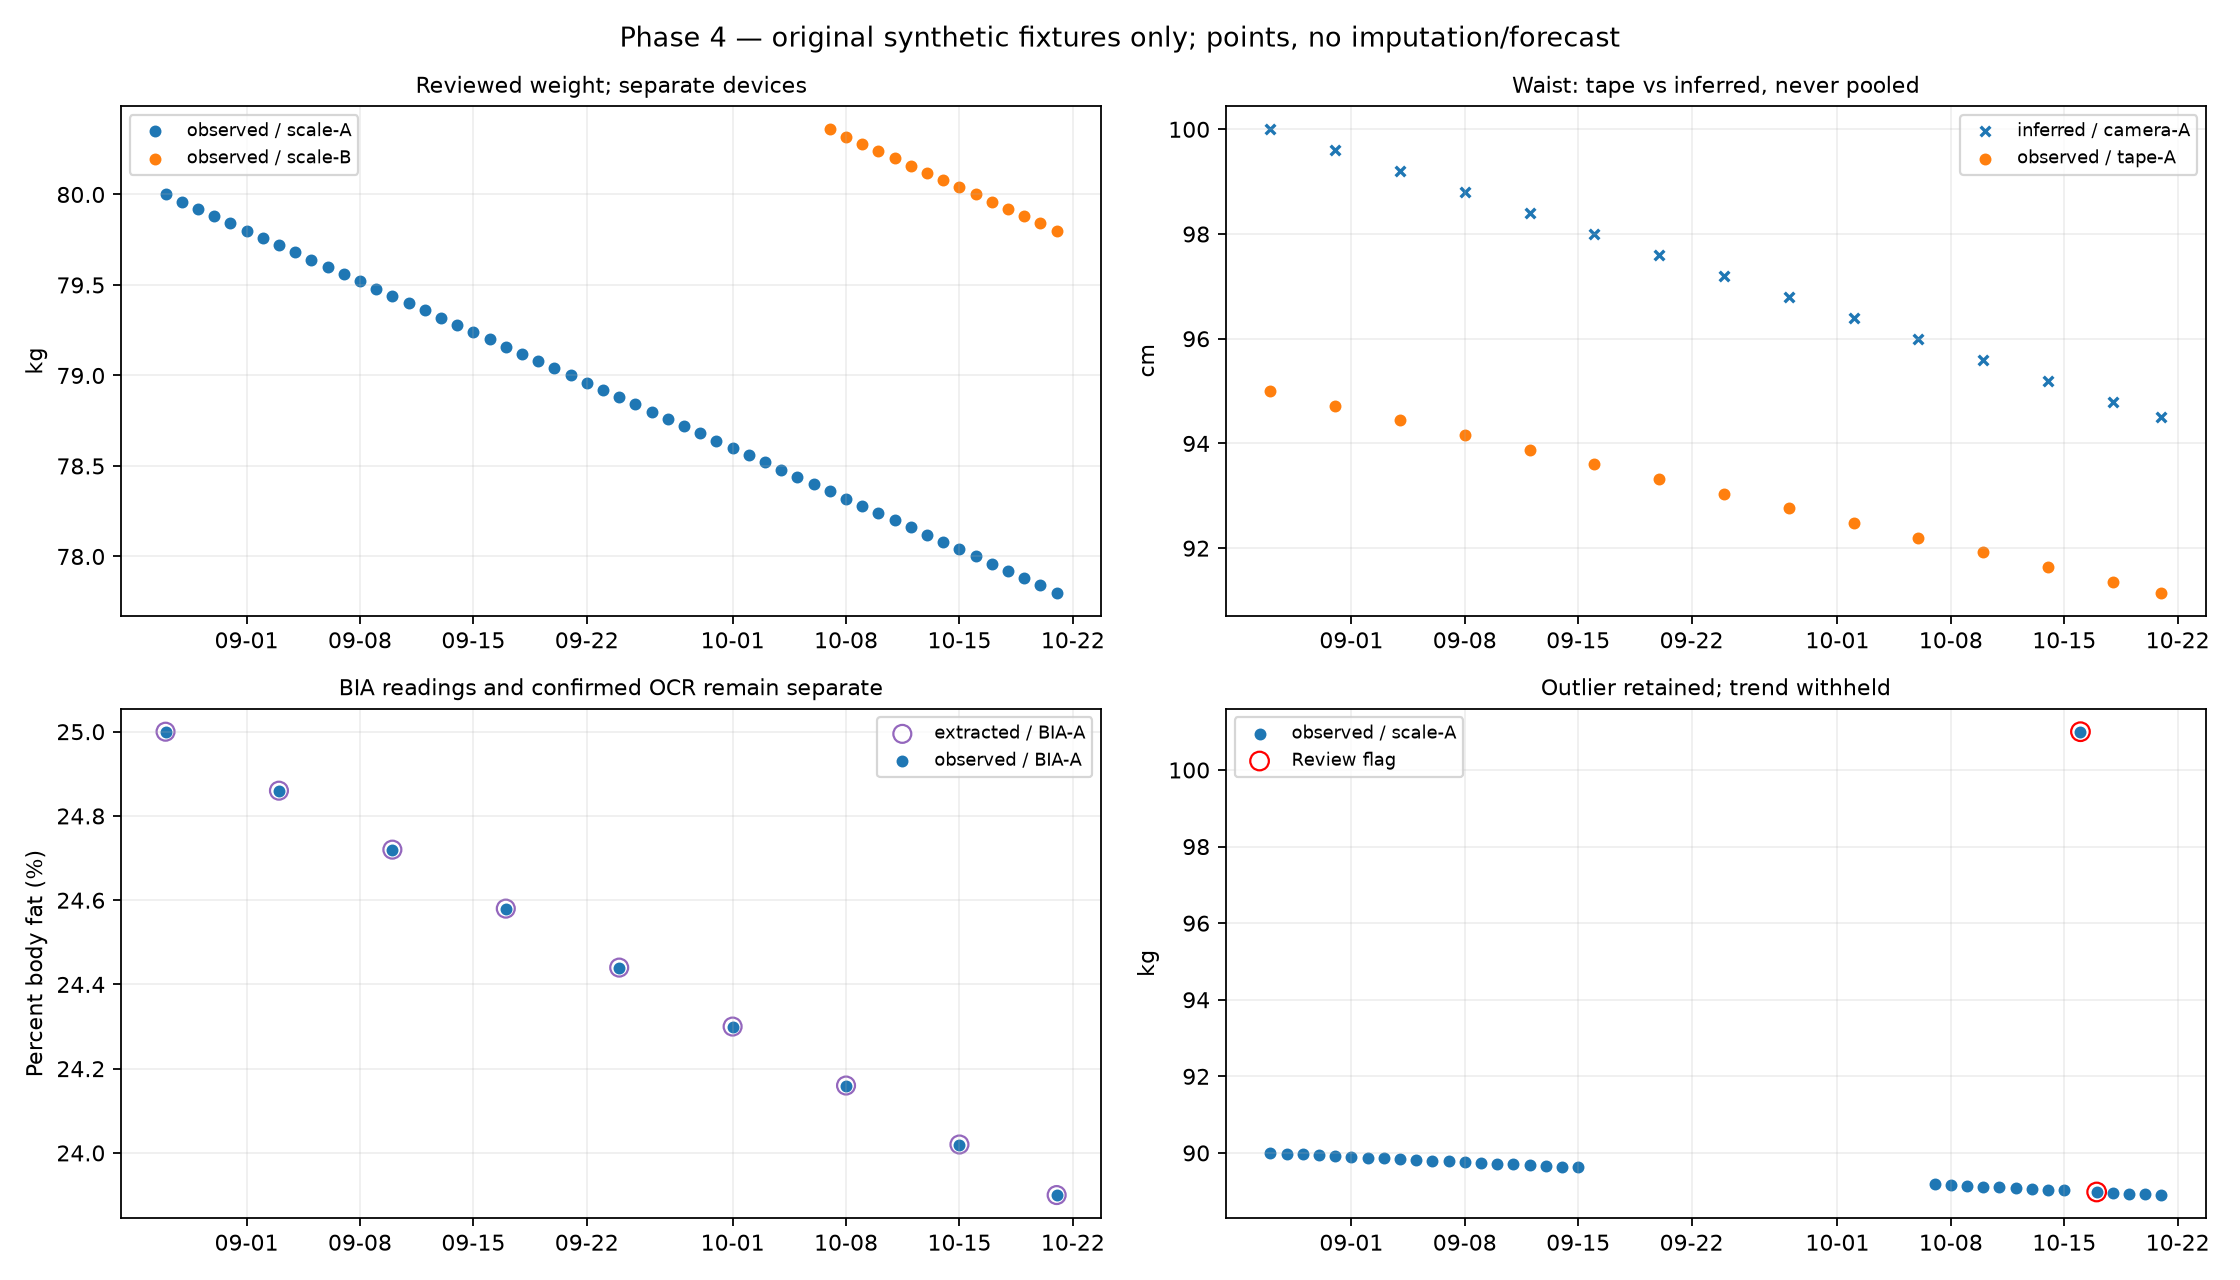

Outlier maximum retained: 101.0


[{'after': '2026-08-27',
  'before': '2026-09-20',
  'days_between_values': 24,
  'days_without_values': 23},
 {'after': '2026-09-20',
  'before': '2026-10-21',
  'days_between_values': 31,
  'days_without_values': 30}]

In [3]:
from PIL import Image
display(Image.open(ROOT / "experiments/body_progress_phase4/progress.png"))
review = next(s for s in progress["series"] if s["subject_id"] == "synthetic-review")
assert review["trend"]["slope_per_week"] is None
print("Outlier maximum retained:", max(day["value"] for day in review["days"] if day["value"] is not None))
sparse = next(s for s in progress["series"] if s["subject_id"] == "synthetic-sparse")
display(sparse["gaps"])
assert len(sparse["days"]) == 3  # No forward-fill/interpolation.

In [4]:
pbf = next(s for s in progress["series"] if s["subject_id"] == "synthetic-steady" and s["field"] == "percent_body_fat" and s["provenance"] == "observed")
assert pbf["recent_week_comparison"]["change_unit"] == "percentage_points"
primary = next(s for s in progress["series"] if s["subject_id"] == "synthetic-steady" and s["field"] == "weight_kg" and s["device_id"] == "scale-A")
display(primary["recent_week_comparison"])
print("Statistical confidence:", primary["trend"]["statistical_confidence"])

{'current': {'start': '2026-10-16',
  'end': '2026-10-22',
  'days_with_values': 6,
  'median': 77.9,
  'has_review_flags': False},
 'previous': {'start': '2026-10-09',
  'end': '2026-10-15',
  'days_with_values': 7,
  'median': 78.16,
  'has_review_flags': False},
 'change': -0.2599999999999909,
 'relative_percent': -0.33265097236436914,
 'change_unit': 'kg'}

Statistical confidence: None


## Error analysis / conclusion

Hệ số -0,28 kg/tuần chỉ là nhãn fixture, không phải mục tiêu/khuyến nghị giảm cân. Không gộp sensor A/B, observed/confirmed-OCR/inferred, protocol hoặc model version. Nhiều lần đo trong ngày không lấn át tuần. PBF đổi theo điểm phần trăm; reference 0 không chia cho 0 và không coi là missing.

Các ngưỡng đổi nhanh, gap/stale, số ngày là engineering heuristics. Trend bị giữ lại nếu cờ chưa xử lý hoặc dữ liệu quá thưa/cũ; không xóa outlier hay đoán ngày còn thiếu. Chưa có longitudinal benchmark thực, device repeatability hoặc calibrated trend confidence. Theil-Sen chỉ mô tả dữ liệu; không forecast/causal/clinical conclusion. [Phương pháp SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.theilslopes.html).